# Experiment 7 — 3-Qubit Bit-Flip and Phase-Flip Codes
**Case Study 5: National Intelligent Transportation System (QML Coursework)**

**Objective:** protect one qubit that carries real traffic information — an angle-encoded junction reading
from the platform — against the two basic kinds of quantum noise, the **bit flip** ($X$ error) and the
**phase flip** ($Z$ error), using the 3-qubit repetition codes. We build, draw and test each code, then measure how
much it reduces the error rate as the hardware noise level $p$ grows.

> **Why this matters for the case study:** Experiments 1–6 ran on an *ideal* simulator. Real quantum hardware is noisy.
> A bit flip on the prediction qubit can turn *Congested* into *Free-flowing* (no signal re-timing is triggered); a phase flip
> silently destroys the phases written by the ZZ feature map of Experiment 2. Error correction is what makes a quantum
> module trustworthy enough to sit inside a safety-relevant traffic system.

## Aim
To implement the 3-qubit bit-flip code and the 3-qubit phase-flip code on a qubit that holds an angle-encoded traffic
reading, detect errors with syndrome measurement, correct them, and compare the logical error rate with an unprotected qubit.

## Theory
**Quantum states cannot simply be copied** (no-cloning theorem), so we cannot back up a qubit the classical way.
Instead, the *information* is spread over several qubits (entanglement) so that one error can be **detected without
measuring the data itself**.

**1. Bit-flip code** (protects against $X$ errors)

$$\alpha|0\rangle+\beta|1\rangle \;\xrightarrow{\text{encode}}\; \alpha|000\rangle+\beta|111\rangle$$

Two parity checks (the **syndrome**) locate a single flipped qubit:

| Syndrome $(s_1,s_2)$ | $s_1=q_0\oplus q_1$, $s_2=q_1\oplus q_2$ | Correction |
|---|---|---|
| 00 | no error | none |
| 10 | $q_0$ flipped | $X$ on $q_0$ |
| 11 | $q_1$ flipped | $X$ on $q_1$ |
| 01 | $q_2$ flipped | $X$ on $q_2$ |

**2. Phase-flip code** (protects against $Z$ errors). A phase flip in the $\{|0\rangle,|1\rangle\}$ basis is a bit flip in the
$\{|+\rangle,|-\rangle\}$ basis, so we reuse the bit-flip code with Hadamard gates around it:

$$\alpha|0\rangle+\beta|1\rangle \;\xrightarrow{\text{encode}}\; \alpha|{+}{+}{+}\rangle+\beta|{-}{-}{-}\rangle$$

**3. Logical error rate.** If each qubit independently suffers the error with probability $p$, the code fails only when
**two or more** qubits are hit:

$$p_L = 3p^2(1-p) + p^3 = 3p^2 - 2p^3$$

This is smaller than $p$ whenever $p < 0.5$, so the code helps when the hardware is not too noisy.

## Case Study 5 — National Intelligent Transportation System (ITS)
A national government is integrating traffic signals, surveillance cameras, GPS devices, emergency vehicles, weather
stations, and autonomous vehicles into one intelligent transportation platform. The platform must continuously:
1. predict traffic flow, 2. optimise signal timing, 3. detect accidents, and 4. recommend alternate routes,

with predictions required within one second.

**Scope of this notebook.** We do *not* error-correct the whole platform — sensors, networks and controllers are classical
and use classical error handling (checksums, redundancy). We protect only the **quantum part**: a single qubit holding
an encoded traffic feature, exactly the kind of qubit produced by $U_{\text{encode}}(x)$ in Experiment 1.

### Symbol mapping for this experiment
| Symbol | Meaning in this experiment |
|---|---|
| $x$ | One real junction snapshot from the dataset; we use its `hour` reading |
| $\theta(x)$ | `hour` scaled to $[0,\pi]$ — the angle used by angle encoding |
| $\lvert\psi(x)\rangle = R_Y(\theta)\lvert0\rangle = \alpha\lvert0\rangle+\beta\lvert1\rangle$ | The **logical** traffic qubit we want to protect ($\alpha=\cos\frac{\theta}{2}$, $\beta=\sin\frac{\theta}{2}$) |
| $\lvert\psi_L\rangle$ | The encoded 3-qubit state: $\alpha\lvert000\rangle+\beta\lvert111\rangle$ (bit-flip) or $\alpha\lvert{+}{+}{+}\rangle+\beta\lvert{-}{-}{-}\rangle$ (phase-flip) |
| $X_k$, $Z_k$ | A bit-flip / phase-flip error on data qubit $k$ — the hardware noise |
| $Z_0Z_1$, $Z_1Z_2$ | **Stabilisers**: the parity checks measured to find the error without reading $\alpha,\beta$ |
| $(s_1,s_2)$ | Syndrome bits measured on two ancilla qubits |
| $p$ | Physical error probability per qubit; $p_L$ = logical error probability after correction |
| Classical decision | Syndrome → which correction to apply (a classical look-up table) |

## 0. Environment setup

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('qiskit_aer') is None:          # installs only on Colab / fresh machines
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'qiskit', 'qiskit-aer', 'pylatexenc', 'ucimlrepo'])

import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import qiskit, qiskit_aer
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
print("qiskit:", qiskit.__version__, "| qiskit-aer:", qiskit_aer.__version__)

qiskit: 2.6.2 | qiskit-aer: 0.18.4


## 1. Dataset and the traffic qubit to protect
**Source:** Metro Interstate Traffic Volume — UCI Machine Learning Repository (id 492, also on Kaggle). 48,204 hourly records of
I-94 traffic volume with weather readings — the same dataset used in Experiments 1–6.

We pick one real **evening rush-hour snapshot**, scale its `hour` reading to $[0,\pi]$ (exactly as in Experiment 1) and
angle-encode it into one qubit. That qubit is the information we will protect.

In [2]:
import os
paths = ['Metro_Interstate_Traffic_Volume.csv', 'data/Metro_Interstate_Traffic_Volume.csv',
         '../data/Metro_Interstate_Traffic_Volume.csv']
local = [p for p in paths if os.path.exists(p)]
if local:
    df = pd.read_csv(local[0])
else:                                                    # Colab: download straight from UCI
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=492); df = pd.concat([d.data.features, d.data.targets], axis=1)

df = df[(df['rain_1h'] < 100) & (df['temp'] > 100)].copy()     # same cleaning as Exp 1-6
df['date_time'] = pd.to_datetime(df['date_time']); df['hour'] = df['date_time'].dt.hour
print("Cleaned shape:", df.shape)

snap = df[(df['hour'] == 17)].iloc[0]                    # a real 17:00 rush-hour reading
theta = snap['hour'] / 23 * np.pi                        # angle encoding: hour -> [0, pi]
alpha, beta = np.cos(theta / 2), np.sin(theta / 2)
print(f"snapshot: {snap['date_time']}  hour={snap['hour']}  traffic_volume={snap['traffic_volume']}")
print(f"theta = {theta:.3f} rad  ->  |psi> = {alpha:.3f}|0> + {beta:.3f}|1>")

Cleaned shape: (48193, 10)
snapshot: 2012-10-02 17:00:00  hour=17  traffic_volume=5791
theta = 2.322 rad  ->  |psi> = 0.398|0> + 0.917|1>


## 2. Tools shared by both codes
`prepare` writes the traffic qubit $|\psi(x)\rangle=R_Y(\theta)|0\rangle$ onto qubit 0.
`check_logical` **undoes** the preparation with $R_Y(-\theta)$ and measures: if the protected state survived perfectly, the
result is always `0`. The fraction of `0`s is therefore the **success probability** of the whole encode → error → correct → decode chain.

In [3]:
sim = AerSimulator()

def run_success(qc, shots=2000):
    # probability that the final 'out' bit is 0  ==  state recovered correctly
    counts = sim.run(qc, shots=shots).result().get_counts()
    good = sum(c for k, c in counts.items() if k.split()[0] == '0')   # 'out' is the last register -> leftmost
    return good / shots

def draw(qc, **kw):
    display(qc.draw('mpl', fold=-1, **kw))

## 3. The 3-qubit bit-flip code
**Circuit stages** (labelled by barriers in the drawing):
1. **Prepare** — $R_Y(\theta)$ on $q_0$: the *feature-dependent* gate that loads the traffic reading.
2. **Encode** — CNOT $q_0\!\to\!q_1$, CNOT $q_0\!\to\!q_2$: copies the *basis value* (not the state) → $\alpha|000\rangle+\beta|111\rangle$.
3. **Error** — an $X$ gate on one data qubit (simulated noise).
4. **Syndrome** — ancilla $a_0$ collects $q_0\oplus q_1$, ancilla $a_1$ collects $q_1\oplus q_2$; both are measured.
5. **Correct** — classical look-up: syndrome → $X$ on the guilty qubit (classically-controlled gates).
6. **Decode + check** — reverse the encoder, undo $R_Y(\theta)$, measure $q_0$.

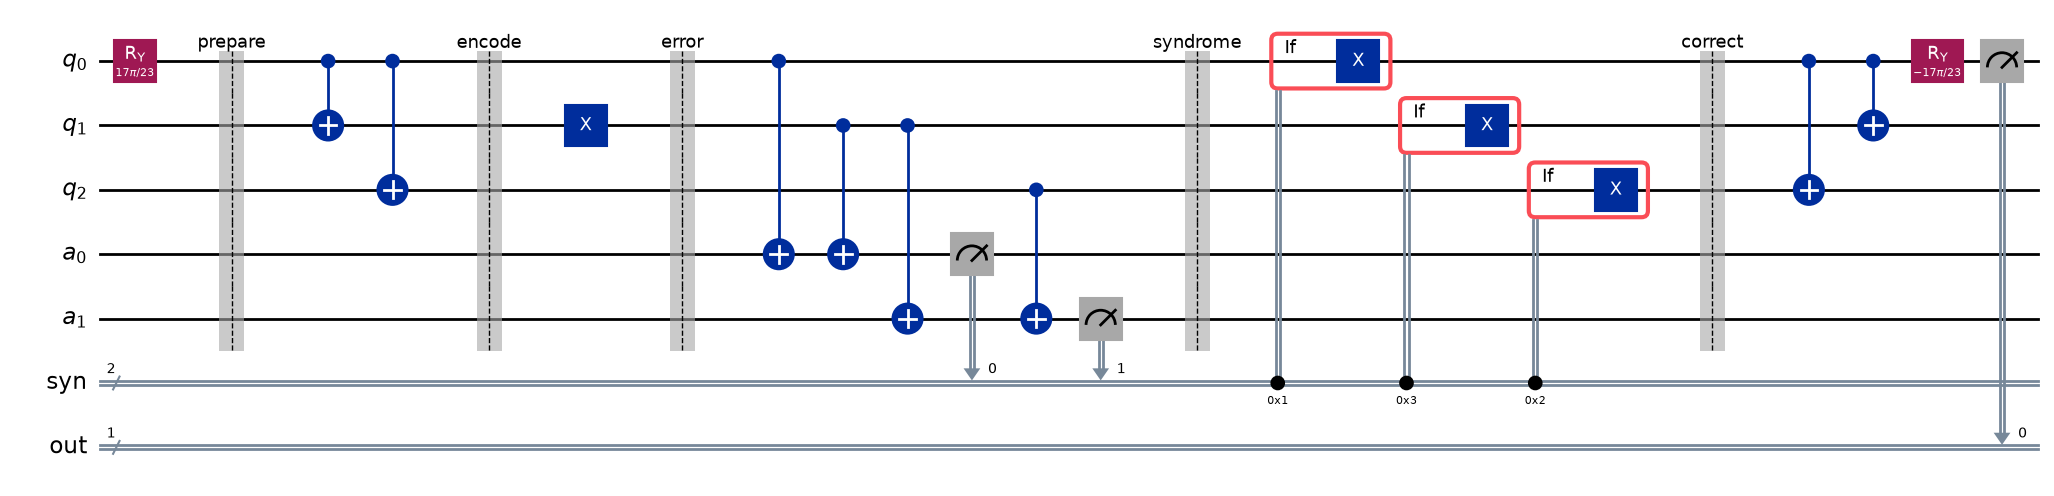

In [4]:
def bit_flip_code(theta, error_qubit=None, error='x', wait=False):
    q = QuantumRegister(3, 'q'); a = QuantumRegister(2, 'a')
    s = ClassicalRegister(2, 'syn'); out = ClassicalRegister(1, 'out')
    qc = QuantumCircuit(q, a, s, out)
    qc.ry(theta, q[0]);                       qc.barrier(label='prepare')
    qc.cx(q[0], q[1]); qc.cx(q[0], q[2]);     qc.barrier(label='encode')
    if error_qubit is not None:
        getattr(qc, error)(q[error_qubit])
    if wait:                                  # used in section 6: noise model acts on these 'id' gates
        qc.id(q)
    qc.barrier(label='error')
    qc.cx(q[0], a[0]); qc.cx(q[1], a[0])      # s1 = q0 xor q1
    qc.cx(q[1], a[1]); qc.cx(q[2], a[1])      # s2 = q1 xor q2
    qc.measure(a, s);                         qc.barrier(label='syndrome')
    for value, target in [(0b01, 0), (0b11, 1), (0b10, 2)]:    # syn register reads (s2 s1)
        with qc.if_test((s, value)):
            qc.x(q[target])
    qc.barrier(label='correct')
    qc.cx(q[0], q[2]); qc.cx(q[0], q[1]); qc.ry(-theta, q[0])
    qc.measure(q[0], out[0])
    return qc

draw(bit_flip_code(theta, error_qubit=1))

### 3.1 Test every possible single bit flip
For each error location we record the measured syndrome and whether the traffic qubit was recovered.

In [5]:
def syndrome_of(qc):
    counts = sim.run(qc, shots=500).result().get_counts()
    syn = max(counts, key=counts.get).split()[1]            # 'syn' register, printed as s2 s1
    return syn[::-1]                                         # report as (s1 s2)

rows = []
for e in [None, 0, 1, 2]:
    qc = bit_flip_code(theta, e)
    rows.append({'error injected': 'none' if e is None else f'X on q{e}',
                 'syndrome (s1 s2)': syndrome_of(qc),
                 'P(recovered)': run_success(qc)})
bit_table = pd.DataFrame(rows); bit_table

,error injected,syndrome (s1 s2),P(recovered)
0,none,00,1.0
1,X on q0,10,1.0
2,X on q1,11,1.0
3,X on q2,01,1.0


## 4. The 3-qubit phase-flip code
Same structure, but the data qubits are moved to the $\{|+\rangle,|-\rangle\}$ basis with Hadamards after encoding
(and moved back before the syndrome check). In that basis a $Z$ error looks exactly like an $X$ error, so the same
parity checks find it.

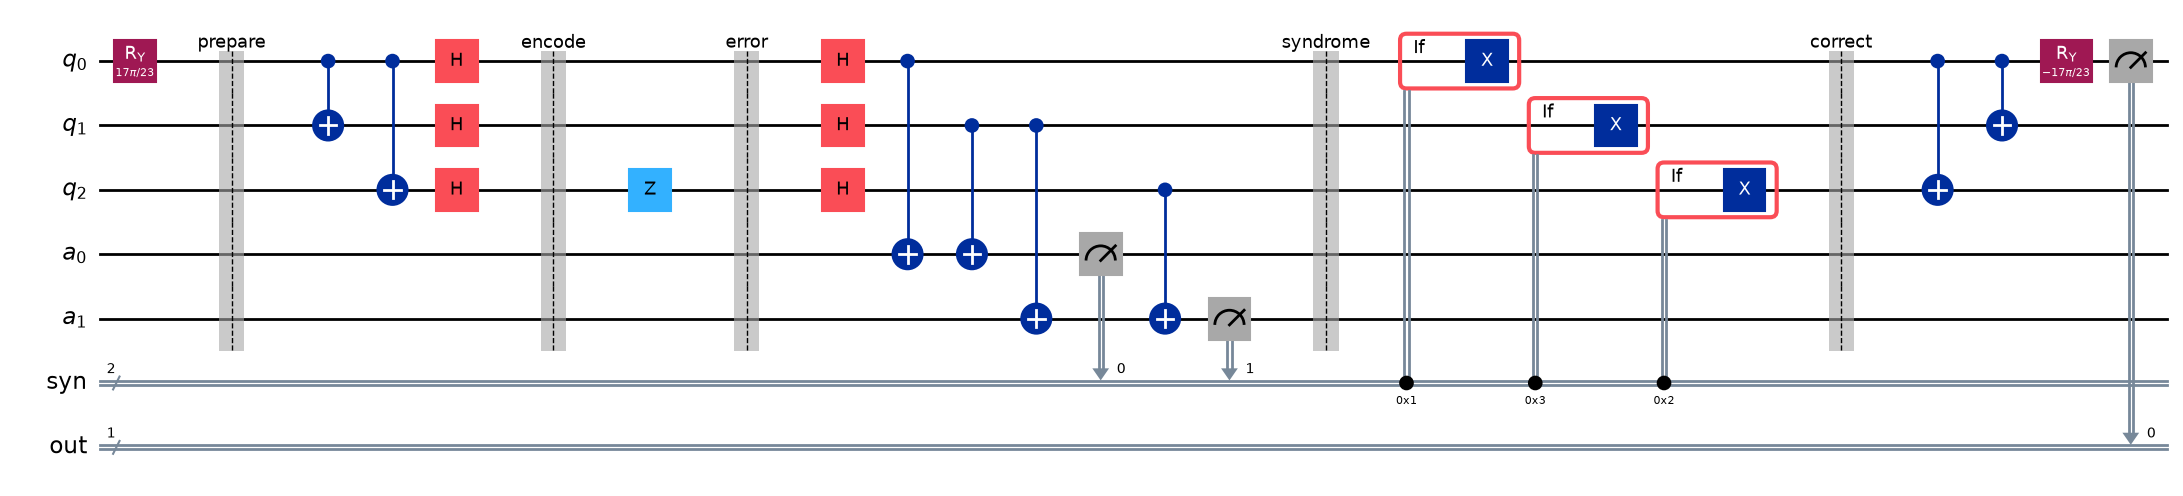

In [6]:
def phase_flip_code(theta, error_qubit=None, error='z', wait=False):
    q = QuantumRegister(3, 'q'); a = QuantumRegister(2, 'a')
    s = ClassicalRegister(2, 'syn'); out = ClassicalRegister(1, 'out')
    qc = QuantumCircuit(q, a, s, out)
    qc.ry(theta, q[0]);                                   qc.barrier(label='prepare')
    qc.cx(q[0], q[1]); qc.cx(q[0], q[2]); qc.h(q);        qc.barrier(label='encode')
    if error_qubit is not None:
        getattr(qc, error)(q[error_qubit])
    if wait:                                  # used in section 6: noise model acts on these 'id' gates
        qc.id(q)
    qc.barrier(label='error')
    qc.h(q)                                               # back to the computational basis
    qc.cx(q[0], a[0]); qc.cx(q[1], a[0]); qc.cx(q[1], a[1]); qc.cx(q[2], a[1])
    qc.measure(a, s);                                     qc.barrier(label='syndrome')
    for value, target in [(0b01, 0), (0b11, 1), (0b10, 2)]:
        with qc.if_test((s, value)):
            qc.x(q[target])
    qc.barrier(label='correct')
    qc.cx(q[0], q[2]); qc.cx(q[0], q[1]); qc.ry(-theta, q[0])
    qc.measure(q[0], out[0])
    return qc

draw(phase_flip_code(theta, error_qubit=2))

In [7]:
rows = []
for e in [None, 0, 1, 2]:
    qc = phase_flip_code(theta, e)
    rows.append({'error injected': 'none' if e is None else f'Z on q{e}',
                 'syndrome (s1 s2)': syndrome_of(qc),
                 'P(recovered)': run_success(qc)})
phase_table = pd.DataFrame(rows); phase_table

,error injected,syndrome (s1 s2),P(recovered)
0,none,00,1.0
1,Z on q0,10,1.0
2,Z on q1,11,1.0
3,Z on q2,01,1.0


## 5. Each code protects against only one type of error
We now inject the *wrong* type of error into each code. This is the key limitation that motivates the 9-qubit Shor code
in Experiment 8.

In [8]:
cross = pd.DataFrame([
    {'code': 'bit-flip code',   'X error on q0': run_success(bit_flip_code(theta, 0, 'x')),
                                'Z error on q0': run_success(bit_flip_code(theta, 0, 'z'))},
    {'code': 'phase-flip code', 'X error on q0': run_success(phase_flip_code(theta, 0, 'x')),
                                'Z error on q0': run_success(phase_flip_code(theta, 0, 'z'))},
])
cross.round(3)

,code,X error on q0,Z error on q0
0,bit-flip code,1.000,0.496
1,phase-flip code,0.472,1.000


The bit-flip code **cannot see** a $Z$ error (the parities $Z_0Z_1, Z_1Z_2$ commute with $Z$), so the phase damage passes
straight through. Likewise the phase-flip code cannot see an $X$ error. *(The success probability under the wrong error is
not 0 because measuring after $R_Y(-\theta)$ only partly reveals a phase error — but it is clearly no longer 1.)*

## 6. Noise sweep: logical error rate vs. physical error rate
Now noise is **random**: after encoding, every data qubit independently suffers the error with probability $p$
(modelled with a Qiskit Aer noise model on an identity "wait" gate). We compare:
* **unprotected** — the bare traffic qubit, error probability $p$,
* **3-qubit code** — measured by simulation, and the theory curve $p_L = 3p^2 - 2p^3$.

**Test state.** §5 showed that our check (undo $R_Y(\theta)$, measure) catches a logical error only *partly* for a general
$\theta$. When either code fails, the leftover error is a **logical bit flip** $\bar X$ (for the phase-flip code, three $Z$ errors
turn $|{+}{+}{+}\rangle$ into $|{-}{-}{-}\rangle$, i.e. logical $|0\rangle\to|1\rangle$). So we test with the logical state $|0\rangle$,
which reveals every such failure — e.g. a *Free-flowing* prediction qubit that would be read as *Congested*.

In [9]:
from qiskit_aer.noise import NoiseModel, pauli_error

def logical_error(kind, p, shots=20000):
    err = pauli_error([('X' if kind == 'bit' else 'Z', p), ('I', 1 - p)])
    nm = NoiseModel(); nm.add_all_qubit_quantum_error(err, ['id'])
    s = AerSimulator(noise_model=nm, seed_simulator=7)
    code_fn = bit_flip_code if kind == 'bit' else phase_flip_code
    test_theta = 0.0                                      # |0> reveals EVERY logical failure (see note)
    counts = s.run(code_fn(test_theta, wait=True), shots=shots).result().get_counts()
    return 1 - sum(c for k, c in counts.items() if k.split()[0] == '0') / shots

ps = [0.0, 0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5]
sweep = pd.DataFrame({'p': ps,
                      'unprotected': ps,
                      'bit-flip code (sim)':   [logical_error('bit', p) for p in ps],
                      'phase-flip code (sim)': [logical_error('phase', p) for p in ps],
                      'theory 3p^2-2p^3':      [3*p**2 - 2*p**3 for p in ps]})
sweep.round(4)

,p,unprotected,bit-flip code (sim),phase-flip code (sim),theory 3p^2-2p^3
0,0.00,0.00,0.0000,0.0000,0.0000
1,0.01,0.01,0.0004,0.0004,0.0003
2,0.02,0.02,0.0011,0.0011,0.0012
3,0.05,0.05,0.0074,0.0074,0.0073
4,0.10,0.10,0.0282,0.0282,0.0280
5,0.15,0.15,0.0614,0.0614,0.0608
6,0.20,0.20,0.1076,0.1076,0.1040
7,0.30,0.30,0.2203,0.2203,0.2160
8,0.40,0.40,0.3590,0.3590,0.3520
9,0.50,0.50,0.5095,0.5095,0.5000


*Why the two simulated columns are identical:* the phase-flip code is exactly the bit-flip code viewed in the
Hadamard basis, so with the same random seed the same error patterns are drawn and lead to the same outcomes.

*Note on "unprotected":* for a bit flip the bare qubit is wrong with probability exactly $p$. We use $p$ as the
unprotected reference for both error types, as is standard; it is the rate the code is trying to beat.

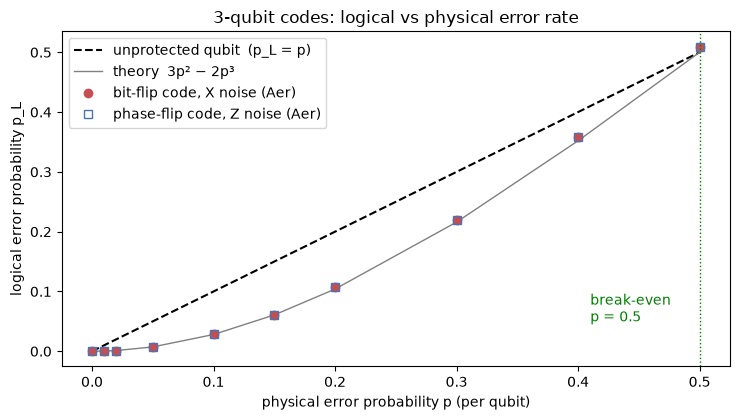

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(sweep.p, sweep.unprotected, 'k--', label='unprotected qubit  (p_L = p)')
ax.plot(sweep.p, sweep['theory 3p^2-2p^3'], color='grey', lw=1, label='theory  3p² − 2p³')
ax.plot(sweep.p, sweep['bit-flip code (sim)'], 'o', color='#C44E52', label='bit-flip code, X noise (Aer)')
ax.plot(sweep.p, sweep['phase-flip code (sim)'], 's', mfc='none', color='#4C72B0', label='phase-flip code, Z noise (Aer)')
ax.axvline(0.5, color='green', ls=':', lw=1); ax.text(0.41, 0.05, 'break-even\np = 0.5', color='green')
ax.set_xlabel('physical error probability p (per qubit)'); ax.set_ylabel('logical error probability p_L')
ax.set_title('3-qubit codes: logical vs physical error rate'); ax.legend(); plt.tight_layout(); plt.show()

## 7. What this means for a traffic prediction
Suppose the prediction qubit of the junction classifier is exposed to bit-flip noise of $p = 5\%$ before it is measured.

In [11]:
p = 0.05
pl = 3*p**2 - 2*p**3
per_day = 24 * 1000        # e.g. 1,000 junctions, one prediction per hour
print(f"unprotected : {p*100:.2f}% of predictions corrupted  -> ~{p*per_day:,.0f} wrong congestion flags per day")
print(f"bit-flip code: {pl*100:.3f}% corrupted              -> ~{pl*per_day:,.0f} per day  ({p/pl:.1f}x fewer)")
print("cost: 3 data qubits + 2 ancillas instead of 1 qubit, plus 8 CNOTs per protected qubit")

unprotected : 5.00% of predictions corrupted  -> ~1,200 wrong congestion flags per day
bit-flip code: 0.725% corrupted              -> ~174 per day  (6.9x fewer)
cost: 3 data qubits + 2 ancillas instead of 1 qubit, plus 8 CNOTs per protected qubit


## 8. Discussion
* **Main result.** Both codes correct *every* single error of the type they are designed for (tables in §3.1 and §4:
  success probability 1.0 for each location) and the simulated logical error rate follows $3p^2-2p^3$ (§6). Below the
  break-even point $p=0.5$ the code always helps, and for realistic small $p$ the gain is large (≈ 7× fewer errors at $p=5\%$).
* **Syndrome measurement does not destroy the data.** The ancillas measure only *parities* ($Z_0Z_1$, $Z_1Z_2$), which are
  identical for $|000\rangle$ and $|111\rangle$. So we learn *where* the error is without learning $\alpha$ or $\beta$ — the traffic
  reading itself is never read out.
* **Limitation.** Each code handles only one error type (§5). Real hardware produces both — and $Z$ errors are exactly what
  corrupts the phase-based ZZ feature map of Experiment 2. Experiment 8 combines both codes into the 9-qubit Shor code.
* **Assumptions.** Errors happen only in one "storage" window, encoding/syndrome gates are perfect and the simulator is ideal
  otherwise. On real devices the extra gates also add noise, which raises the effective $p$.

## 9. Classical vs. quantum: which stages are quantum here?
| Stage | Classical or quantum? |
|---|---|
| Sensor reading, cleaning, scaling `hour` → θ | Classical |
| Preparing $R_Y(\theta)\lvert0\rangle$, encoding into 3 qubits | Quantum |
| Noise (X / Z errors) | Quantum (physical hardware effect) |
| Syndrome extraction with ancillas | Quantum |
| Syndrome → correction look-up table | **Classical** decision (fast, in real time) |
| Applying the correction, decoding | Quantum |
| Using the prediction to re-time signals / reroute | Classical |

## 10. Summary
* Encoded a real, angle-encoded traffic reading into the 3-qubit **bit-flip** and **phase-flip** codes, with all circuits drawn and labelled.
* Showed that the syndrome uniquely identifies every single error and that the correction recovers the state with probability 1.
* Showed that each code fails against the other error type — the motivation for Shor's code.
* Measured logical error rate vs physical error rate and matched it to theory $p_L = 3p^2-2p^3$.

**References:** J. Hogue, *Metro Interstate Traffic Volume*, UCI ML Repository, 2019. M. Nielsen & I. Chuang, *Quantum
Computation and Quantum Information*, Ch. 10, Cambridge Univ. Press, 2010.